<a href="https://colab.research.google.com/github/mirraaditiir2025cse-cpu/FDS-CS23334-all-Lab-Experiments/blob/main/FDS_Lab_experiment_16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

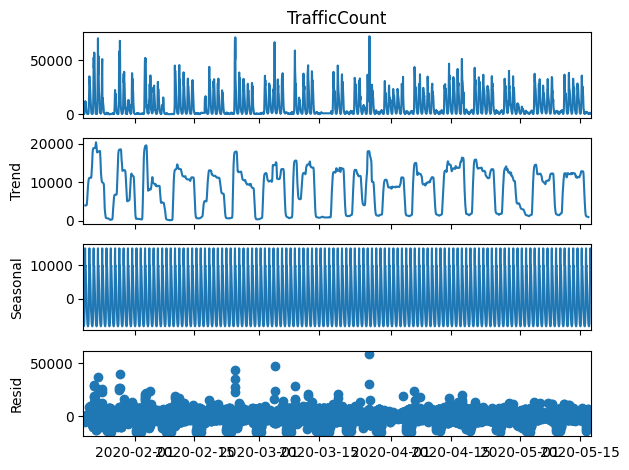

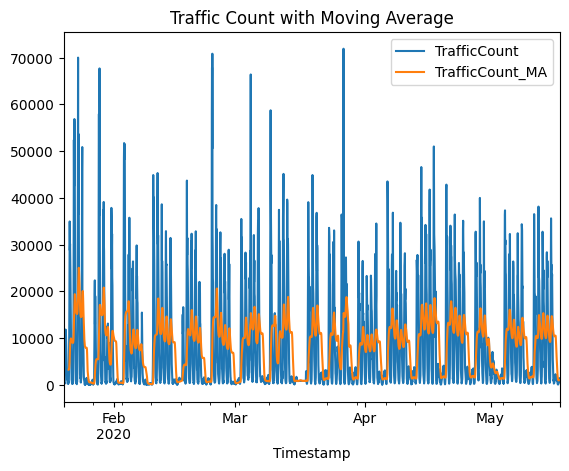

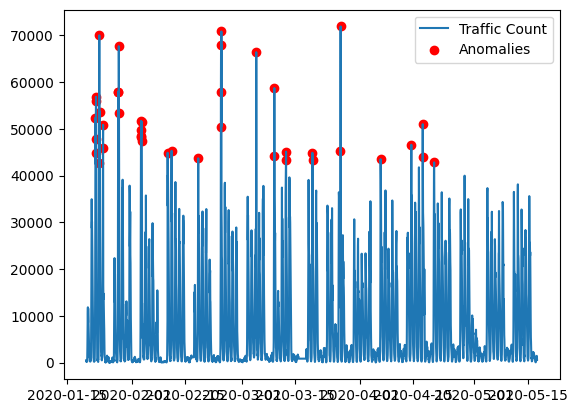

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# Load dataset with proper parsing
data = pd.read_csv('/content/web_traffic.csv', parse_dates=['Timestamp'], index_col='Timestamp')

# Resample to a fixed hourly frequency to handle any missing intervals
data = data.resample('h').mean().ffill()

# Time Series Decomposition using 'TrafficCount'
decomposition = seasonal_decompose(data['TrafficCount'], model='additive')
decomposition.plot()
plt.show()

# Moving Average
data['TrafficCount_MA'] = data['TrafficCount'].rolling(window=30).mean()
data[['TrafficCount', 'TrafficCount_MA']].plot()
plt.title('Traffic Count with Moving Average')
plt.show()

# Anomaly Detection
data['TrafficCount_Z'] = (data['TrafficCount'] - data['TrafficCount'].mean()) / data['TrafficCount'].std()
anomalies = data[data['TrafficCount_Z'].abs() > 3]
plt.plot(data.index, data['TrafficCount'], label='Traffic Count')
plt.scatter(anomalies.index, anomalies['TrafficCount'], color='red', label='Anomalies')
plt.legend()
plt.show()